# KITScenes — Aerial imagery

One ego-aligned orthophoto crop per frame, cut from the DOP20 tiles of the German state WMS services (Hesse: Frankfurt;
Baden-Württemberg: Karlsruhe, Sindelfingen) with `kitscenes.aerial`. The release ships the raw tiles (JPEG, 0.2 m/px,
~2 GB) in `<root>/aerial/`; crops are cut from them when asked for, with no preparation, and reading never touches the
network. Uses: bird's-eye-view supervision, map checks, visualization.

**Needs:** `kitscenes[aerial,map,viz]` installed as in the README and the tiles:
they come with every download (`kitscenes download ROOT`, the areas of the selected scenes; third-party imagery,
`aerial/ATTRIBUTION.md`; `--no-aerial` leaves them out). For the example scene of notebook 01 that is the Frankfurt
area, 0.28 GB. Only scenes with poses in a map frame get crops: the test and map_change_test splits are placed with their city's origin, the test-e2e
splits (poses relative to the first pose) get none.

**Licences:** the imagery comes under the terms of the state services, see `<root>/aerial/ATTRIBUTION.md`
(Baden-Württemberg: Datenlizenz Deutschland – Namensnennung 2.0, source note e.g. "LGL-BW (2026) Datenlizenz
Deutschland – Namensnennung – Version 2.0, www.lgl-bw.de"; Hesse: free use, a source note must mention changes).

In [1]:
import os
import time

import matplotlib.pyplot as plt
import numpy as np

import kitscenes
from kitscenes.aerial import AerialCrops, AerialTiles, build_tile_store

%matplotlib inline
plt.rcParams["figure.dpi"] = 72  # small figures

DATASET_ROOT = os.environ.get("KITSCENES_ROOT", "/data/kitscenes")  # or an absolute path
SCENE_ID = "c34c778f-ad8c-0aa9-7e1a-c86a73f887c7"  # the example scene (notebook 01); any scene UUID on disk works
TILE_STORE = None  # a writable folder (~10 GB) for section 5, e.g. "/scratch/kitscenes_tiles"

from kitscenes.map import MLConverter, Region, has_ml_converter
from kitscenes.visualization import plot_top_down

ROI = (60.0, 30.0)  # (longitudinal_m, lateral_m), centred on the ego

## 1. The tiles, and crops on the fly

`AerialTiles` reads the tiles where the download put them: one zip per 10 km area (read in place) or, after
`kitscenes extract ROOT`, extracted JPEGs. `crops = ds.use_aerial(roi=...)` gives crops cut on
the fly from them, `crops[frame]` the crop of a frame: each tile a crop touches is decoded once and kept in a bounded
cache, so frames in order are cheap. `ROI` is part of the crops' ID (`dop20_res020_roi60x30_ego_v1`).

In [2]:
print(AerialTiles(DATASET_ROOT))
ds = kitscenes.open(DATASET_ROOT)  # every split under the root
crops = ds.use_aerial(roi=ROI)
scene = ds[SCENE_ID]
print(crops)
print(crops.coverage([scene]).summary())

AerialTiles(['/data/kitscenes/aerial'], 'dop20_res020_tile2048': 797 tiles in 3 areas, jpeg)
AerialCrops(AerialTiles(['/data/kitscenes/aerial'], 'dop20_res020_tile2048': 797 tiles in 3 areas, jpeg), roi=(60.0, 30.0), backend='cv2')


dop20_res020_roi60x30_ego_v1: 220 frames with a crop in 1 scenes; 0 frames lack raw tiles (0 scenes incomplete); 0 scenes without a map origin


## 2. One crop

`crops[frame]` is an `(H, W, 3)` uint8 RGB array of `round(lateral / 0.2)` × `round(longitudinal / 0.2)` pixels.
The ego (`frame.pose`) is the centre pixel; forward points right, left points up. A frame without a crop raises
`AerialUnavailable` with state `WITHHELD_BY_SPLIT` or `DROPPED` (no tiles there, no pose);
`crops.at(frame, missing="none")` returns None instead. `frame.aerial()` is a shortcut for the crops that
`ds.use_aerial` attached last.

(150, 300, 3) uint8


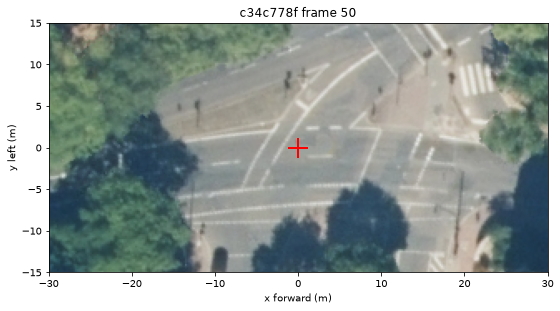

In [3]:
frame = scene[min(50, len(scene) - 1)]
crop = crops[frame]
print(crop.shape, crop.dtype)

L, W = ROI
extent = [-L / 2, L / 2, -W / 2, W / 2]  # x forward (right), y left (up), metres
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.imshow(crop, extent=extent)
ax.plot(0, 0, "r+", markersize=20, markeredgewidth=2)
ax.set(xlabel="x forward (m)", ylabel="y left (m)", title=f"{scene.id[:8]} frame {frame.index}")
plt.show()

## 3. Map labels and lidar over the crop

The ML converter's labels and the lidar points are in the same base frame, so they go straight over the crop
(`plot_top_down(..., orientation="horizontal")` draws driving to the right):

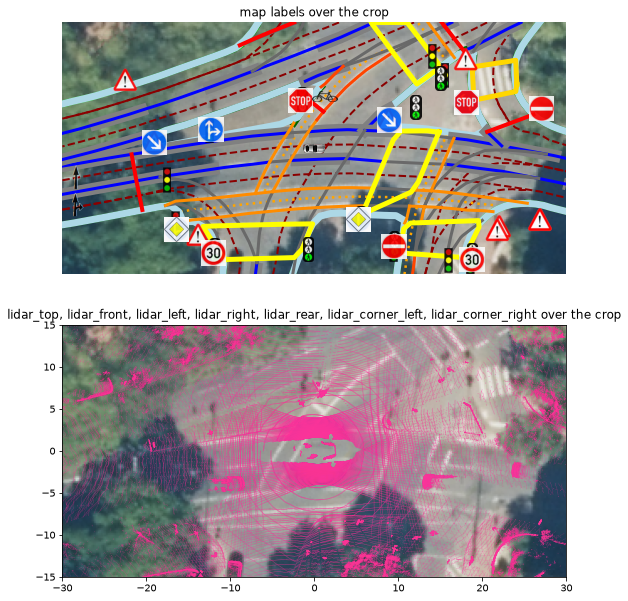

In [4]:
fig, axes = plt.subplots(2, 1, figsize=(10, 10))
axes[0].imshow(crop, extent=extent, zorder=0)
if has_ml_converter():
    conv = MLConverter.for_scene(scene, region=Region(ahead=L / 2, behind=L / 2, left=W / 2, right=W / 2))
    plot_top_down(conv(frame.pose), axes[0], orientation="horizontal", extent=(L / 2, W / 2), show_edges=False,
                  show_legend=False)
axes[0].set_title("map labels over the crop")

cloud = frame.fused_lidar()
xyz = cloud.xyz
inside = (np.abs(xyz[:, 0]) < L / 2) & (np.abs(xyz[:, 1]) < W / 2)
reflectivity = cloud.reflectivity[inside].astype(np.float32)
strength = np.clip(reflectivity / np.percentile(reflectivity, 99), 0, 1)
pink = np.tile([1.0, 0.2, 0.6, 0.0], (len(strength), 1))
pink[:, 3] = 0.30 + 0.55 * strength  # 30 % where the return is weak, up to 85 % where it is strong
axes[1].imshow(crop, extent=extent)
axes[1].scatter(xyz[inside, 0], xyz[inside, 1], s=0.6, c=pink, linewidths=0)
axes[1].set(xlim=(-L / 2, L / 2), ylim=(-W / 2, W / 2), title=f"{', '.join(cloud.sensor)} over the crop")
plt.show()

Several frames at once, and only the road: the ground-labelled points (`labels=True`, notebook 03) of the frames
around this one, moved into its base frame with the frame poses, one point per 10 cm cell with the mean
reflectivity of its points. The road markings reflect strongly and line up with the ones in the crop.

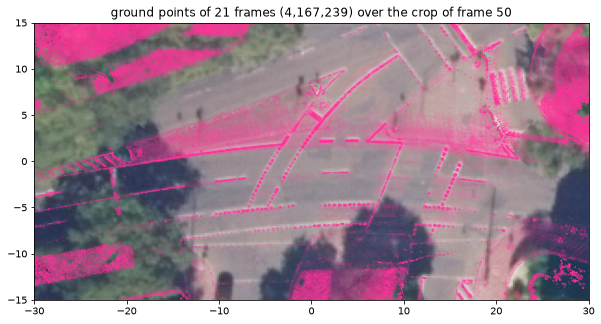

In [5]:
around = range(max(0, frame.index - 20), min(len(scene), frame.index + 21), 2)
to_here = np.linalg.inv(frame.T_world_base)  # world -> the base frame of this frame
points, reflectivity = [np.zeros((0, 3), np.float32)], [np.zeros(0, np.float32)]
for k in around:
    sweep = scene[k].fused_lidar(labels=True, missing="none")  # deskewed, in the base frame of frame k
    if sweep is None or "ground" not in sweep.attrs:
        continue
    ground = sweep["ground"]
    points.append(kitscenes.transform_points(to_here @ scene[k].T_world_base, sweep.xyz[ground]))
    reflectivity.append(sweep.reflectivity[ground].astype(np.float32))
xyz, reflectivity = np.concatenate(points), np.concatenate(reflectivity)
inside = (np.abs(xyz[:, 0]) < L / 2) & (np.abs(xyz[:, 1]) < W / 2)

CELL = 0.1  # m: one point per cell, with the mean reflectivity of the points in it
nx, ny = int(round(L / CELL)), int(round(W / CELL))
ix = np.clip(((xyz[inside, 0] + L / 2) / CELL).astype(int), 0, nx - 1)
iy = np.clip(((xyz[inside, 1] + W / 2) / CELL).astype(int), 0, ny - 1)
count = np.bincount(ix * ny + iy, minlength=nx * ny)
mean = np.bincount(ix * ny + iy, weights=reflectivity[inside], minlength=nx * ny) / np.maximum(count, 1)
cells = np.flatnonzero(count)
x, y = (cells // ny + 0.5) * CELL - L / 2, (cells % ny + 0.5) * CELL - W / 2
# opacity from the reflectivity: the weaker half (asphalt) nearly transparent, the strongest 1 % (markings) opaque
weak, strong = np.percentile(mean[cells], [50, 99]) if len(cells) else (0.0, 1.0)
strength = np.clip((mean[cells] - weak) / max(strong - weak, 1e-6), 0, 1)
pink = np.tile([1.0, 0.2, 0.6, 0.0], (len(cells), 1))
pink[:, 3] = 0.03 + 0.92 * strength
fig, ax = plt.subplots(figsize=(10, 5))
ax.imshow(crop, extent=extent)
ax.scatter(x, y, s=2.5, c=pink, linewidths=0)
ax.set(xlim=(-L / 2, L / 2), ylim=(-W / 2, W / 2),
       title=f"ground points of {len(around)} frames ({int(inside.sum()):,}) over the crop of frame {frame.index}")
plt.show()

## 4. Along the drive

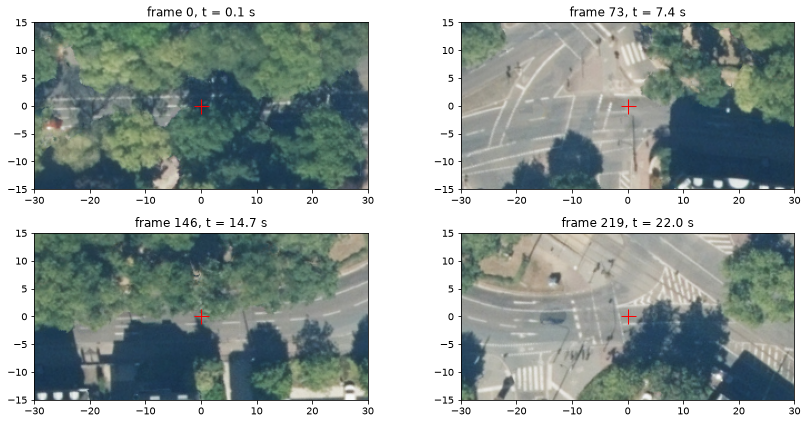

In [6]:
indices = np.linspace(0, len(scene) - 1, 4).astype(int)
fig, axes = plt.subplots(2, 2, figsize=(12, 6))
for ax, i in zip(axes.flat, indices):
    image = crops.at(scene[i], missing="none")
    if image is not None:
        ax.imshow(image, extent=extent)
        ax.plot(0, 0, "r+", markersize=15)
    ax.set_title(f"frame {i}, t = {scene[i].t_s:.1f} s" + ("" if image is not None else ": no crop"))
plt.tight_layout()
plt.show()

## 5. For training: a tile store

Decoding a JPEG tile takes tens of milliseconds, and in random order nearly every crop needs new tiles. A tile store
is the tiles converted once into uncompressed `.npy` files (~10 GB, under a minute): a crop then memory-maps only its
window and takes about a millisecond, in any order. `AerialCrops` pickles to its folders, so it goes into DataLoader
workers with the dataset. `crops.crop((easting, northing), yaw)` cuts a crop at any EPSG:25832 pose.

In [7]:
if TILE_STORE is not None:
    store = build_tile_store(TILE_STORE, DATASET_ROOT)  # once; a rerun converts only what is missing
    fast = ds.use_aerial(roi=ROI, tiles=store)
    frames = [scene[int(i)] for i in np.random.default_rng(0).integers(0, len(scene), 20)]
    t = time.perf_counter()
    for f in frames:
        fast[f]
    print(f"{(time.perf_counter() - t) / len(frames) * 1e3:.1f} ms per crop from the tile store")

## 6. Optional: a prepared crop cache

For tools that read image files, `prepare_aerials` writes one PNG per frame, cut with the same function, into a
writable folder (default `<root>/aerial`), only what is missing, and reports the frames it could not cut. On the
command line: `kitscenes aerial prepare ROOT --splits train val --roi 60 30 --cache-dir DIR`.

In [8]:
# cache = ds.filter(scene_ids=[SCENE_ID]).prepare_aerials(roi=ROI, cache_dir="/scratch/kitscenes_aerial")
# print(cache.coverage.summary())
# ds.use_aerial(cache.cache_id, cache_dir="/scratch/kitscenes_aerial")  # later, in a new process

## 7. Optional: DINOv3 features

If the DINOv3 feature tiles are under the root (`aerial/features/`, with the full download or with `--aerial-features`),
`features = ds.use_aerial_features(roi=ROI)` gives the features around each frame, `features[frame]`: one cell per
token (1.28 m), from the last block by default. The default is north-up: a `NorthUpFeatures` with the stored tokens
around the ego, `(L, C, S, S)` float32, and the pose. North-up is the default because the features are not
rotation-equivariant: a token describes its north-up image patch whichever way the crop is turned, so a model
should get the tokens as stored and handle the rotation itself (`docs/aerial_features.md`).
`orientation="ego"` resamples the tokens into the ego frame, `(L, C, H, W)` like the image crop, which is fine for a
picture: the first three principal components, shown as RGB, give areas the features see as alike the same colour.

For the example scene, `kitscenes download "$KITSCENES_ROOT" --scenes c34c778f-ad8c-0aa9-7e1a-c86a73f887c7 --aerial-features`
adds the features of its area (Frankfurt, 104 GB). Without them the cell below says so and draws nothing.

AerialFeatures('/data/kitscenes/aerial/features/dinov3_vitl16_sat493m_dop10_res008_tile2048': 4 tiles in 1 areas, layers [4, 11, 17, 23], 1024 channels)
north-up: tokens (1, 1024, 57, 57), ego heading 44° from east


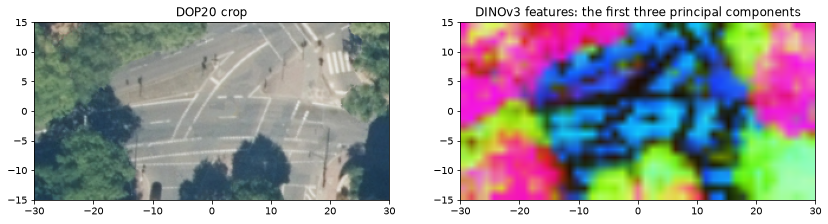

In [9]:
from kitscenes.aerial import AerialFeatures

try:
    print(AerialFeatures(DATASET_ROOT))
except FileNotFoundError:
    print("no DINOv3 feature tiles under this root")
else:
    window = ds.use_aerial_features(roi=ROI)[frame]  # north-up, the default: the stored tokens and the pose
    print(f"north-up: tokens {window.tokens.shape}, ego heading {np.degrees(window.yaw):.0f}° from east")
    tokens = ds.use_aerial_features(roi=ROI, orientation="ego")[frame][-1]  # (C, H, W): the last block, ego-aligned
    x = tokens.reshape(len(tokens), -1).T
    x = x - x.mean(axis=0)
    pcs = x @ np.linalg.svd(x, full_matrices=False)[2][:3].T
    rgb = 1 / (1 + np.exp(-2 * pcs / pcs.std(axis=0)))  # whitened, squashed into 0..1
    fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
    axes[0].imshow(crop, extent=extent)
    axes[0].set_title("DOP20 crop")
    axes[1].imshow(rgb.reshape(*tokens.shape[1:], 3), extent=extent, interpolation="bilinear")
    axes[1].set_title("DINOv3 features: the first three principal components")
    plt.show()